In [46]:
import numpy as np
import pandas as pd
import torch 
import torch.nn as nn
import matplotlib.pyplot as plt
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torchmetrics import MetricCollection, Accuracy, Precision, Recall, F1Score

df = pd.read_csv("public_transport_delays.csv")

df['event_type'] = df['event_type'].fillna('None')
df['hour'] = pd.to_datetime(df['time']).dt.hour

cols_to_drop = ['trip_id', 'date', 'time', 'scheduled_departure', 'scheduled_arrival', 
                'actual_departure_delay_min', 'actual_arrival_delay_min',
                'origin_station', 'destination_station'] # Станції поки приберемо для простоти
df = df.drop(columns=cols_to_drop)

categorical_cols = ['transport_type', 'route_id', 'weather_condition', 'event_type', 'season']
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

df = df.astype(float)

X = df.drop("delayed", axis=1)
y = df["delayed"]

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.22, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values.reshape(-1, 1), dtype=torch.float32)
X_val_scaled_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values.reshape(-1, 1), dtype=torch.float32)
X_test_scaled_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values.reshape(-1, 1), dtype=torch.float32)

input_dim = X.shape[1]
print(len(df))
print(f"Нова кількість вхідних ознак: {input_dim}")

ValueError: could not convert string to float: 'T00000'

In [39]:
print(df.value_counts(y))

delayed
1.0    1499
0.0     501
Name: count, dtype: int64


In [40]:
class MultiLayerPerceptronClassifier(nn.Module):
    def __init__(self, input_dim, activation_function = nn.ReLU):
        super(MultiLayerPerceptronClassifier, self).__init__()
        self.fc1 = nn.Linear(input_dim, 12)
        self.fc2 = nn.Linear(12, 8)
        self.output = nn.Linear(8, 2)
        self.activation_function = activation_function()
    def forward(self, x):
        x = self.activation_function(self.fc1(x))
        x = self.activation_function(self.fc2(x))
        x = self.output(x)
        return x
    

In [41]:
class MultiLayerPerceptronClassifier(nn.Module):
    def __init__(self, input_dim, activation_function = nn.ReLU):
        super(MultiLayerPerceptronClassifier, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64) 
        self.fc2 = nn.Linear(64, 32)        
        self.output = nn.Linear(32, 2)
        self.activation_function = activation_function()
    def forward(self, x):
        x = self.activation_function(self.fc1(x))
        x = self.activation_function(self.fc2(x))
        x = self.output(x)
        return x

In [42]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0, restore_best_weights=True):
        self.patience = patience 
        self.min_delta = min_delta 
        self.restore_best_weights = restore_best_weights 
        self.best_loss = None
        self.counter = 0
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict()
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict()
            self.counter = 0

In [43]:
def perform_learning(epochs, optimizer_name, activation_function_name, early_stopping_enabled = True):
    activations = {'ReLU': nn.ReLU, 'Sigmoid': nn.Sigmoid, 'Tanh': nn.Tanh}
    activation_function = activations[activation_function_name]
    early_stopping = EarlyStopping()
    model = MultiLayerPerceptronClassifier(input_dim, activation_function)
    optimizers = {
    'SGD': optim.SGD(model.parameters(), lr=0.001),
    'RMSprop': optim.RMSprop(model.parameters(), lr=0.001),
    'Adam': optim.Adam(model.parameters(), lr=0.001),
    'Adadelta': optim.Adadelta(model.parameters(), lr=1.0),
    'Adagrad': optim.Adagrad(model.parameters(), lr=0.001),
    'Adamax': optim.Adamax(model.parameters(), lr=0.001),
    'Nadam': optim.NAdam(model.parameters(), lr=0.001)
    }
    weights = torch.tensor([3.0, 1.0], dtype=torch.float32)
    criterion = nn.CrossEntropyLoss(weight = weights)    
    train_loss_history = []
    val_loss_history = []
    optimizer = optimizers[optimizer_name]
    metrics = MetricCollection({
        "accuracy": Accuracy(task="binary"),
        "precision": Precision(task="binary"),
        "recall": Recall(task="binary"),
        "f1": F1Score(task="binary")
    })
    already_stopped = False
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        train_logits = model(X_train_scaled_tensor)
        train_loss = criterion(train_logits, y_train_tensor.squeeze().long())
        train_loss.backward()
        optimizer.step()
        train_loss_history.append(train_loss.item())
        
        model.eval()
        metrics.reset()
        with torch.no_grad():
            val_logits = model(X_val_scaled_tensor)
            val_loss = criterion(val_logits, y_val_tensor.squeeze().long())
            val_probabilites = torch.softmax(val_logits, dim = 1)
            _, val_predictions = torch.max(val_probabilites, 1)
            if not already_stopped:
                step_metrics = metrics(val_predictions, y_val_tensor.squeeze().long())
            val_loss_history.append(val_loss.item())
            early_stopping(val_loss.item(), model)
        
        if early_stopping.early_stop and early_stopping_enabled and not already_stopped:
            print(f"--- [INFO] Early stopping triggered at epoch {epoch+1} for {optimizer_name} ---")
            already_stopped = True
            
        
        if((epoch + 1) % 5 == 0 and not early_stopping.early_stop):
            print(f'Optimizer: {optimizer_name}, Function: {activation_function_name}, Epoch [{epoch+1}/{epochs}], Train Loss: {train_loss.item():.4f}, Validation Loss: {val_loss.item():.4f}, Acc: {step_metrics["accuracy"]}',)
    
    if early_stopping.restore_best_weights:
        model.load_state_dict(early_stopping.best_model_state)
    
    return train_loss_history, val_loss_history, step_metrics, model

In [44]:
optimizer_names = ['SGD', 'RMSprop', 'Adam', 'Adadelta', 'Adagrad', 'Adamax', 'Nadam']
activation_function_names = ['ReLU', 'Sigmoid', 'Tanh']
results = []
best_model = None
best_f1 = 0

Optimizer: SGD, Function: ReLU, Epoch [5/1000], Train Loss: 0.6981, Validation Loss: 0.6960, Acc: 0.2929292917251587
Optimizer: SGD, Function: ReLU, Epoch [10/1000], Train Loss: 0.6980, Validation Loss: 0.6960, Acc: 0.2929292917251587
Optimizer: SGD, Function: ReLU, Epoch [15/1000], Train Loss: 0.6980, Validation Loss: 0.6959, Acc: 0.2954545319080353
Optimizer: SGD, Function: ReLU, Epoch [20/1000], Train Loss: 0.6979, Validation Loss: 0.6959, Acc: 0.2954545319080353
Optimizer: SGD, Function: ReLU, Epoch [25/1000], Train Loss: 0.6979, Validation Loss: 0.6959, Acc: 0.2954545319080353
Optimizer: SGD, Function: ReLU, Epoch [30/1000], Train Loss: 0.6979, Validation Loss: 0.6958, Acc: 0.2954545319080353
Optimizer: SGD, Function: ReLU, Epoch [35/1000], Train Loss: 0.6978, Validation Loss: 0.6958, Acc: 0.29797980189323425
Optimizer: SGD, Function: ReLU, Epoch [40/1000], Train Loss: 0.6978, Validation Loss: 0.6958, Acc: 0.29797980189323425
Optimizer: SGD, Function: ReLU, Epoch [45/1000], Train 

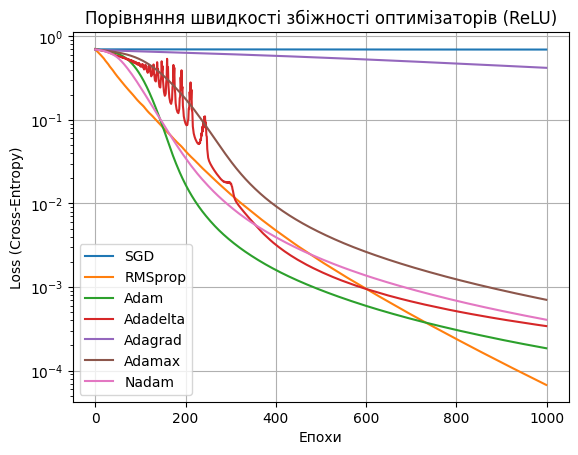

Optimizer: SGD, Function: Sigmoid, Epoch [5/1000], Train Loss: 0.9931, Validation Loss: 0.9916, Acc: 0.24747474491596222
Optimizer: SGD, Function: Sigmoid, Epoch [10/1000], Train Loss: 0.9823, Validation Loss: 0.9809, Acc: 0.24747474491596222
Optimizer: SGD, Function: Sigmoid, Epoch [15/1000], Train Loss: 0.9718, Validation Loss: 0.9705, Acc: 0.24747474491596222
Optimizer: SGD, Function: Sigmoid, Epoch [20/1000], Train Loss: 0.9617, Validation Loss: 0.9604, Acc: 0.24747474491596222
Optimizer: SGD, Function: Sigmoid, Epoch [25/1000], Train Loss: 0.9518, Validation Loss: 0.9506, Acc: 0.24747474491596222
Optimizer: SGD, Function: Sigmoid, Epoch [30/1000], Train Loss: 0.9422, Validation Loss: 0.9410, Acc: 0.24747474491596222
Optimizer: SGD, Function: Sigmoid, Epoch [35/1000], Train Loss: 0.9329, Validation Loss: 0.9318, Acc: 0.24747474491596222
Optimizer: SGD, Function: Sigmoid, Epoch [40/1000], Train Loss: 0.9239, Validation Loss: 0.9228, Acc: 0.24747474491596222
Optimizer: SGD, Function:

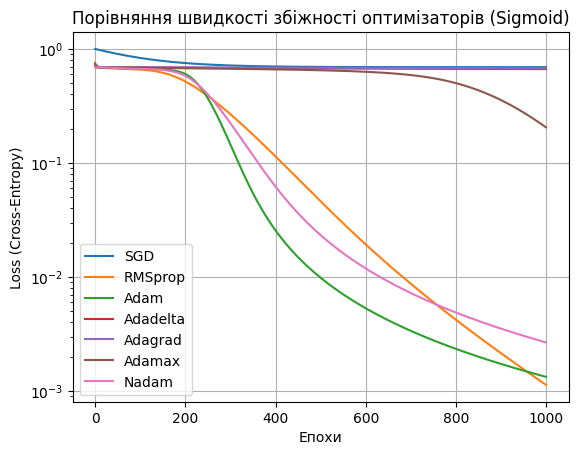

Optimizer: SGD, Function: Tanh, Epoch [5/1000], Train Loss: 0.6999, Validation Loss: 0.7020, Acc: 0.4141414165496826
Optimizer: SGD, Function: Tanh, Epoch [10/1000], Train Loss: 0.6998, Validation Loss: 0.7019, Acc: 0.41161617636680603
Optimizer: SGD, Function: Tanh, Epoch [15/1000], Train Loss: 0.6998, Validation Loss: 0.7019, Acc: 0.41161617636680603
Optimizer: SGD, Function: Tanh, Epoch [20/1000], Train Loss: 0.6997, Validation Loss: 0.7019, Acc: 0.41161617636680603
Optimizer: SGD, Function: Tanh, Epoch [25/1000], Train Loss: 0.6997, Validation Loss: 0.7019, Acc: 0.41161617636680603
Optimizer: SGD, Function: Tanh, Epoch [30/1000], Train Loss: 0.6996, Validation Loss: 0.7019, Acc: 0.41161617636680603
Optimizer: SGD, Function: Tanh, Epoch [35/1000], Train Loss: 0.6996, Validation Loss: 0.7019, Acc: 0.41161617636680603
Optimizer: SGD, Function: Tanh, Epoch [40/1000], Train Loss: 0.6996, Validation Loss: 0.7019, Acc: 0.4141414165496826
Optimizer: SGD, Function: Tanh, Epoch [45/1000], Tr

KeyboardInterrupt: 

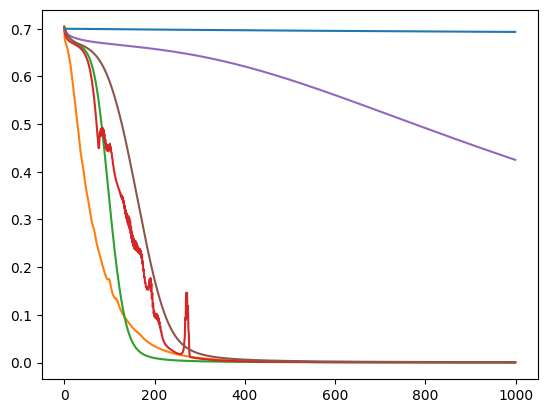

In [45]:
for activation_function_name in activation_function_names:
    for optimizer in optimizer_names:
        train_loss_history, val_loss_history, final_metrics, model = perform_learning(1000, optimizer, activation_function_name)
        current_f1 = final_metrics["f1"].item()
        if(current_f1 > best_f1):
            best_model = model
            best_f1 = current_f1
        plt.plot(train_loss_history, label=optimizer)
        
        results.append({
            'Activation': activation_function_name,
            'Optimizer': optimizer,
            'Accuracy': final_metrics['accuracy'].item(),
            'Precision': final_metrics['precision'].item(),
            'Recall': final_metrics['recall'].item(),
            'F1-Score': final_metrics['f1'].item()
        })
    plt.title(f'Порівняння швидкості збіжності оптимізаторів ({activation_function_name})')
    plt.xlabel('Епохи')
    plt.ylabel('Loss (Cross-Entropy)')
    plt.yscale('log')  
    plt.legend()
    plt.grid(True)
    plt.show()

In [34]:
results_df = pd.DataFrame(results)
print(results_df.sort_values(by='F1-Score', ascending=False))

   Activation Optimizer  Accuracy  Precision    Recall  F1-Score
7     Sigmoid       SGD  0.648990   0.729231  0.822917  0.773246
1        ReLU   RMSprop  0.631313   0.717791  0.812500  0.762215
12    Sigmoid    Adamax  0.606061   0.717105  0.756944  0.736486
8     Sigmoid   RMSprop  0.585859   0.715278  0.715278  0.715278
15       Tanh   RMSprop  0.606061   0.761905  0.666667  0.711111
2        ReLU      Adam  0.588384   0.732342  0.684028  0.707361
6        ReLU     Nadam  0.570707   0.734127  0.642361  0.685185
20       Tanh     Nadam  0.555556   0.708955  0.659722  0.683453
3        ReLU  Adadelta  0.580808   0.779817  0.590278  0.671937
5        ReLU    Adamax  0.553030   0.726531  0.618056  0.667917
18       Tanh   Adagrad  0.545455   0.714286  0.625000  0.666667
16       Tanh      Adam  0.530303   0.705645  0.607639  0.652985
11    Sigmoid   Adagrad  0.537879   0.719665  0.597222  0.652751
17       Tanh  Adadelta  0.542929   0.739910  0.572917  0.645793
13    Sigmoid     Nadam  

In [35]:
def perform_learning_analysis(epochs, optimizer_name, activation_function_name):
    train_loss_history, val_loss_history, _, _ = perform_learning(epochs, optimizer_name, activation_function_name)
    plt.figure(figsize=(10, 6))
    plt.plot(train_loss_history, label='Train Loss')
    plt.plot(val_loss_history, label='Validation Loss', linestyle='--')
    plt.title(f'Аналіз перенавчання ({optimizer_name} + {activation_function_name})')
    plt.xlabel('Епохи')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

Optimizer: SGD, Function: ReLU, Epoch [5/1000], Train Loss: 0.6959, Validation Loss: 0.6964, Acc: 0.3207070827484131
Optimizer: SGD, Function: ReLU, Epoch [10/1000], Train Loss: 0.6957, Validation Loss: 0.6964, Acc: 0.32575756311416626
--- [INFO] Early stopping triggered at epoch 11 for SGD ---


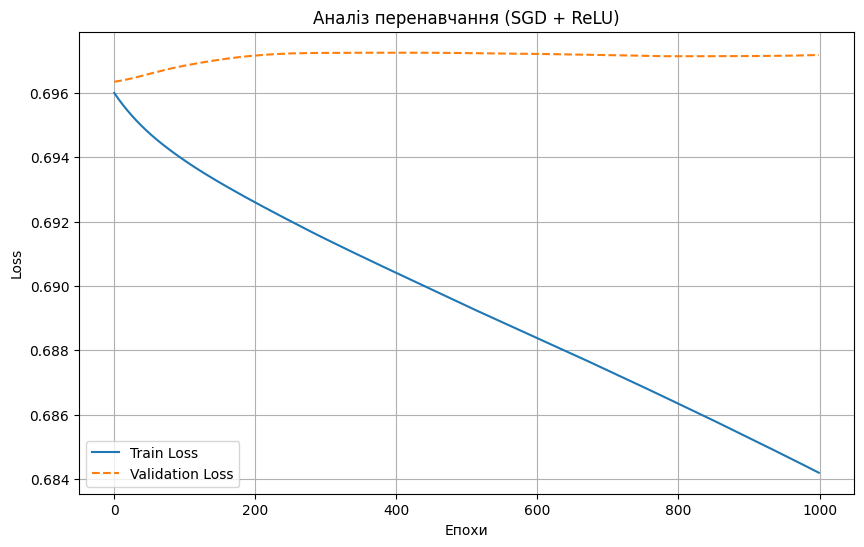

Optimizer: RMSprop, Function: ReLU, Epoch [5/1000], Train Loss: 0.6833, Validation Loss: 0.6965, Acc: 0.5075757503509521
Optimizer: RMSprop, Function: ReLU, Epoch [10/1000], Train Loss: 0.6579, Validation Loss: 0.7028, Acc: 0.5101010203361511
--- [INFO] Early stopping triggered at epoch 14 for RMSprop ---


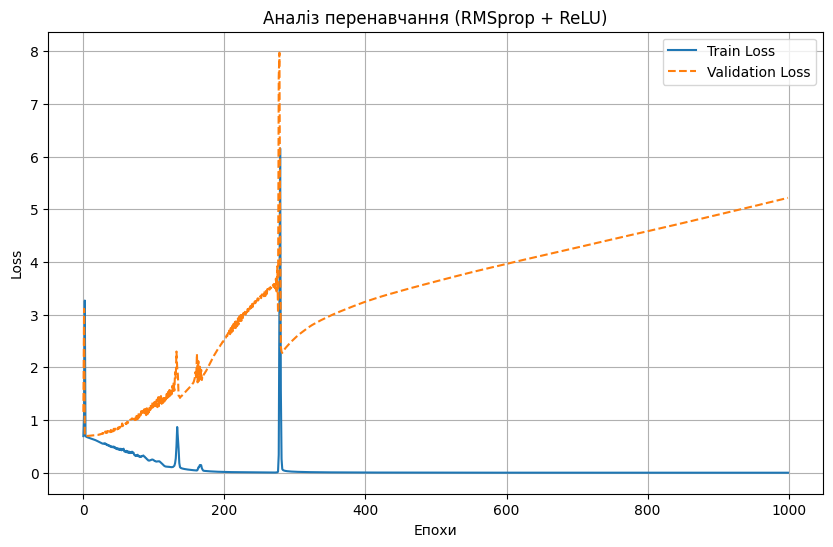

Optimizer: Adam, Function: ReLU, Epoch [5/1000], Train Loss: 0.6601, Validation Loss: 0.7169, Acc: 0.5479797720909119
Optimizer: Adam, Function: ReLU, Epoch [10/1000], Train Loss: 0.5865, Validation Loss: 0.7672, Acc: 0.5707070827484131
--- [INFO] Early stopping triggered at epoch 11 for Adam ---


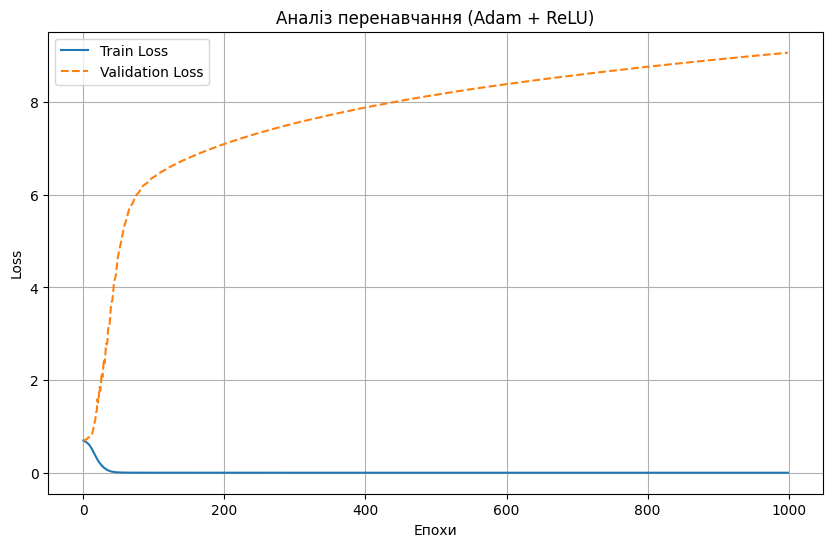

Optimizer: Adadelta, Function: ReLU, Epoch [5/1000], Train Loss: 0.6930, Validation Loss: 0.6969, Acc: 0.3914141356945038
Optimizer: Adadelta, Function: ReLU, Epoch [10/1000], Train Loss: 0.6879, Validation Loss: 0.6989, Acc: 0.4166666567325592
--- [INFO] Early stopping triggered at epoch 13 for Adadelta ---


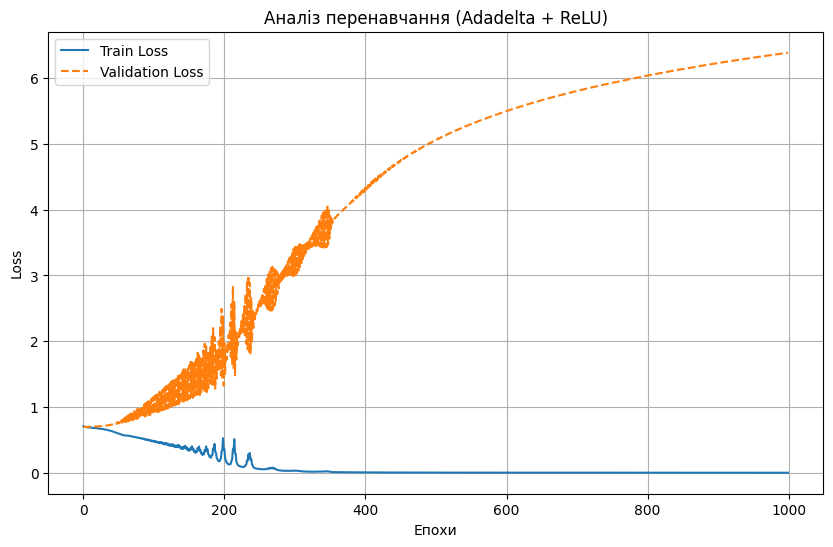

Optimizer: Adagrad, Function: ReLU, Epoch [5/1000], Train Loss: 0.6678, Validation Loss: 0.6980, Acc: 0.44949495792388916
Optimizer: Adagrad, Function: ReLU, Epoch [10/1000], Train Loss: 0.6235, Validation Loss: 0.7170, Acc: 0.5757575631141663
--- [INFO] Early stopping triggered at epoch 11 for Adagrad ---


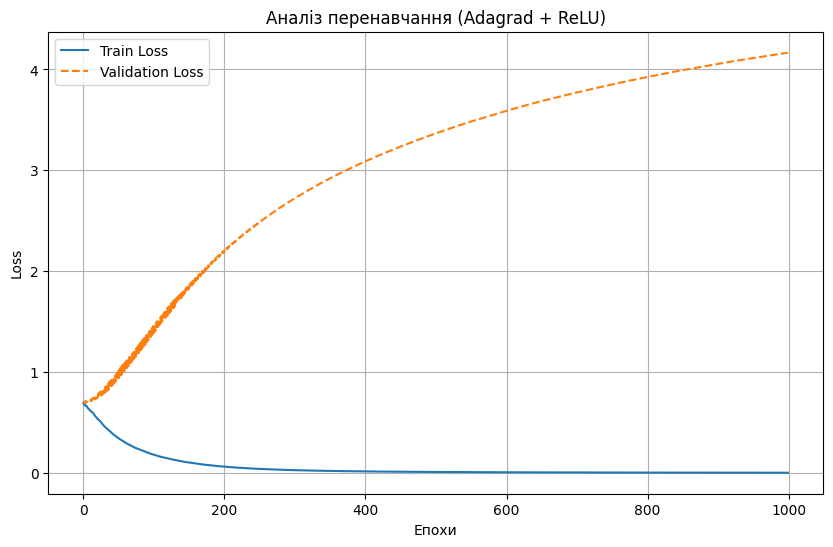

Optimizer: Adamax, Function: ReLU, Epoch [5/1000], Train Loss: 0.6639, Validation Loss: 0.7055, Acc: 0.5808081030845642
Optimizer: Adamax, Function: ReLU, Epoch [10/1000], Train Loss: 0.6147, Validation Loss: 0.7365, Acc: 0.5656565427780151
--- [INFO] Early stopping triggered at epoch 12 for Adamax ---


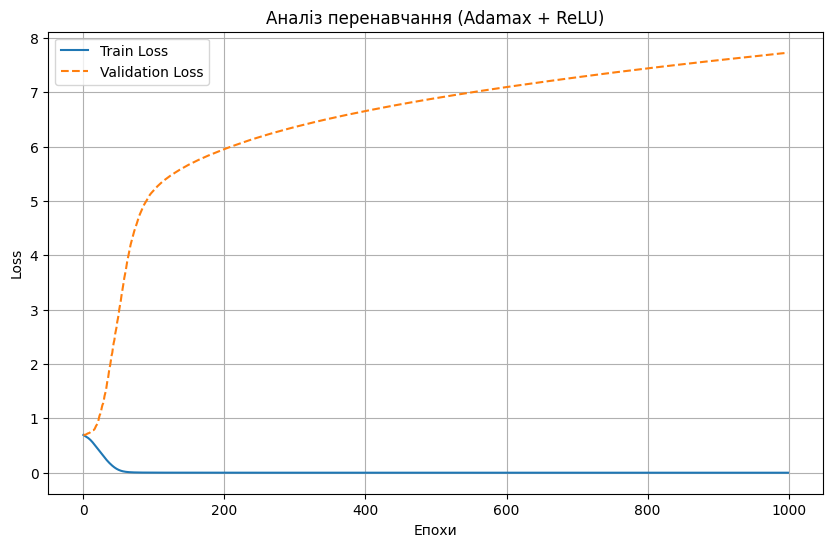

Optimizer: Nadam, Function: ReLU, Epoch [5/1000], Train Loss: 0.6575, Validation Loss: 0.7038, Acc: 0.4343434274196625
Optimizer: Nadam, Function: ReLU, Epoch [10/1000], Train Loss: 0.6001, Validation Loss: 0.7657, Acc: 0.5883838534355164
--- [INFO] Early stopping triggered at epoch 11 for Nadam ---


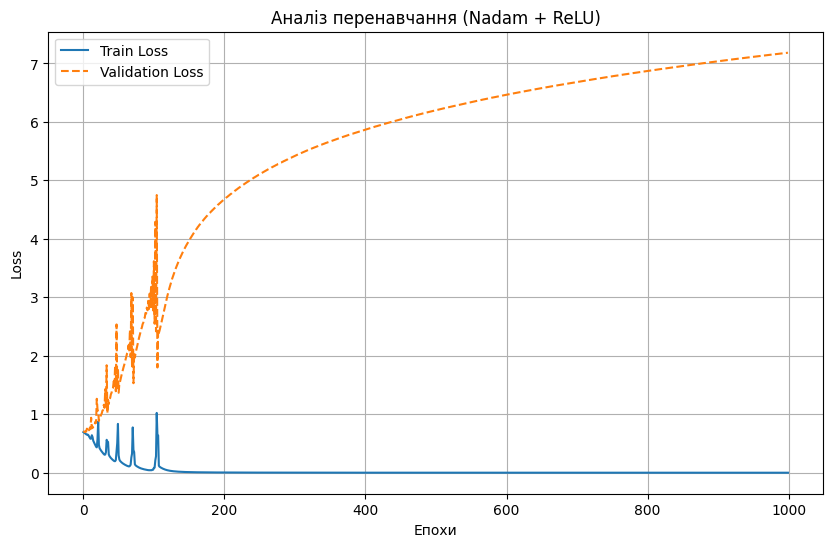

Optimizer: SGD, Function: Sigmoid, Epoch [5/1000], Train Loss: 0.7005, Validation Loss: 0.6930, Acc: 0.27272728085517883
Optimizer: SGD, Function: Sigmoid, Epoch [10/1000], Train Loss: 0.6978, Validation Loss: 0.6921, Acc: 0.27272728085517883
Optimizer: SGD, Function: Sigmoid, Epoch [15/1000], Train Loss: 0.6961, Validation Loss: 0.6917, Acc: 0.27272728085517883
Optimizer: SGD, Function: Sigmoid, Epoch [20/1000], Train Loss: 0.6950, Validation Loss: 0.6918, Acc: 0.27272728085517883
Optimizer: SGD, Function: Sigmoid, Epoch [25/1000], Train Loss: 0.6944, Validation Loss: 0.6919, Acc: 0.27272728085517883
--- [INFO] Early stopping triggered at epoch 27 for SGD ---


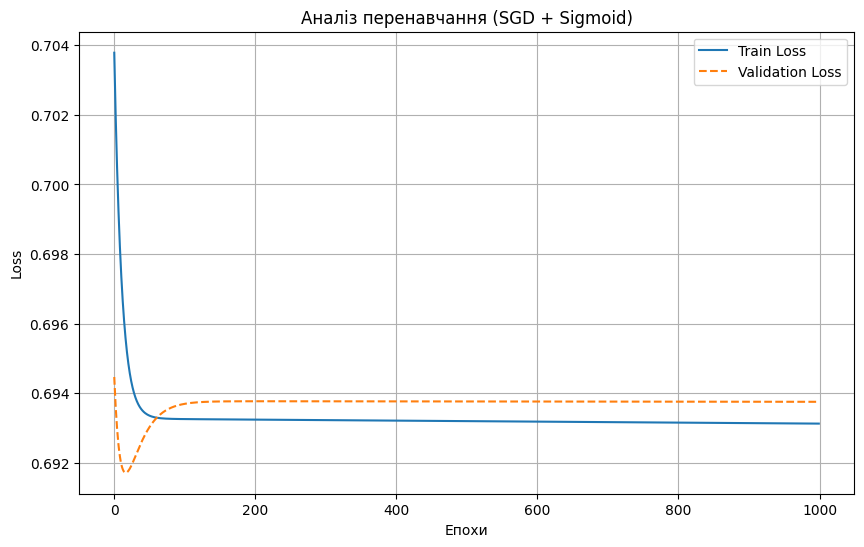

Optimizer: RMSprop, Function: Sigmoid, Epoch [5/1000], Train Loss: 0.6888, Validation Loss: 0.6960, Acc: 0.5303030014038086
Optimizer: RMSprop, Function: Sigmoid, Epoch [10/1000], Train Loss: 0.6758, Validation Loss: 0.7059, Acc: 0.5252525210380554
--- [INFO] Early stopping triggered at epoch 13 for RMSprop ---


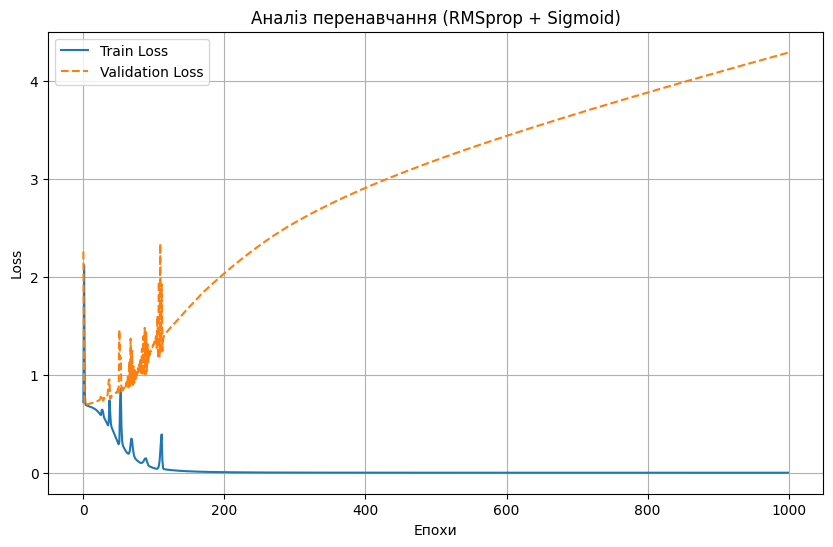

Optimizer: Adam, Function: Sigmoid, Epoch [5/1000], Train Loss: 0.7174, Validation Loss: 0.7268, Acc: 0.7272727489471436
Optimizer: Adam, Function: Sigmoid, Epoch [10/1000], Train Loss: 0.6985, Validation Loss: 0.6976, Acc: 0.27272728085517883
--- [INFO] Early stopping triggered at epoch 12 for Adam ---


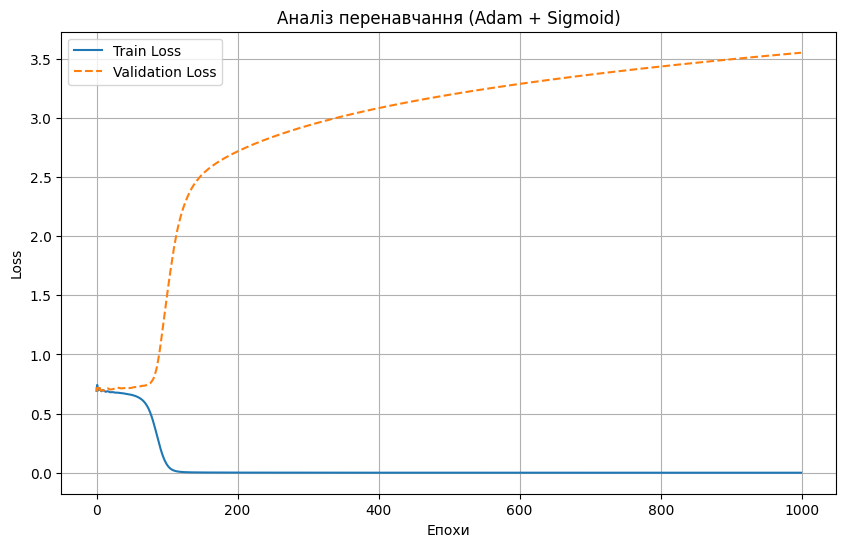

Optimizer: Adadelta, Function: Sigmoid, Epoch [5/1000], Train Loss: 0.6932, Validation Loss: 0.6937, Acc: 0.6641414165496826
Optimizer: Adadelta, Function: Sigmoid, Epoch [10/1000], Train Loss: 0.6932, Validation Loss: 0.6937, Acc: 0.6767676472663879
--- [INFO] Early stopping triggered at epoch 11 for Adadelta ---


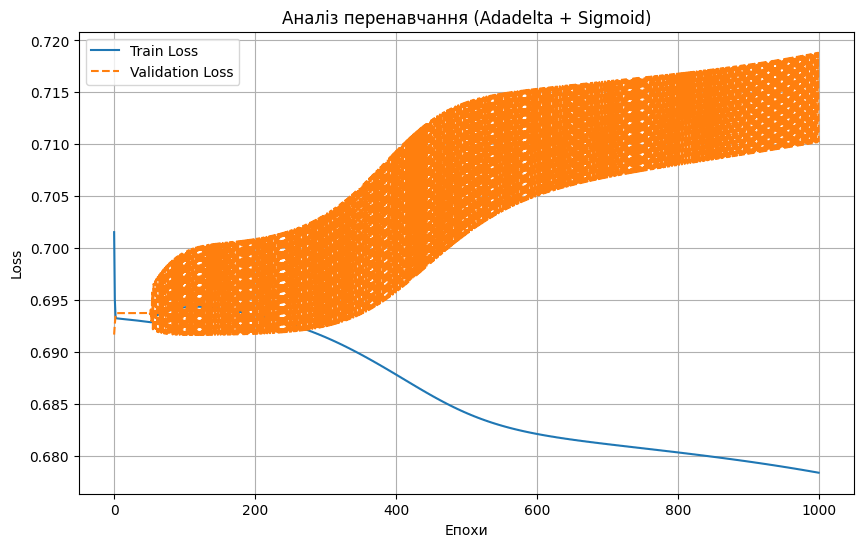

Optimizer: Adagrad, Function: Sigmoid, Epoch [5/1000], Train Loss: 0.6909, Validation Loss: 0.6958, Acc: 0.5404040217399597
Optimizer: Adagrad, Function: Sigmoid, Epoch [10/1000], Train Loss: 0.6891, Validation Loss: 0.6967, Acc: 0.5252525210380554
--- [INFO] Early stopping triggered at epoch 12 for Adagrad ---


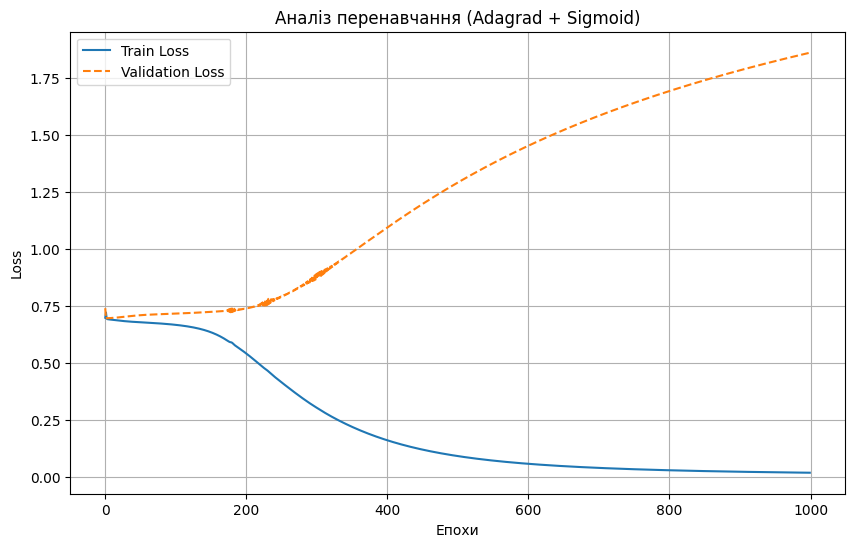

Optimizer: Adamax, Function: Sigmoid, Epoch [5/1000], Train Loss: 0.6931, Validation Loss: 0.7080, Acc: 0.7272727489471436
Optimizer: Adamax, Function: Sigmoid, Epoch [10/1000], Train Loss: 0.6888, Validation Loss: 0.6945, Acc: 0.3484848439693451
--- [INFO] Early stopping triggered at epoch 13 for Adamax ---


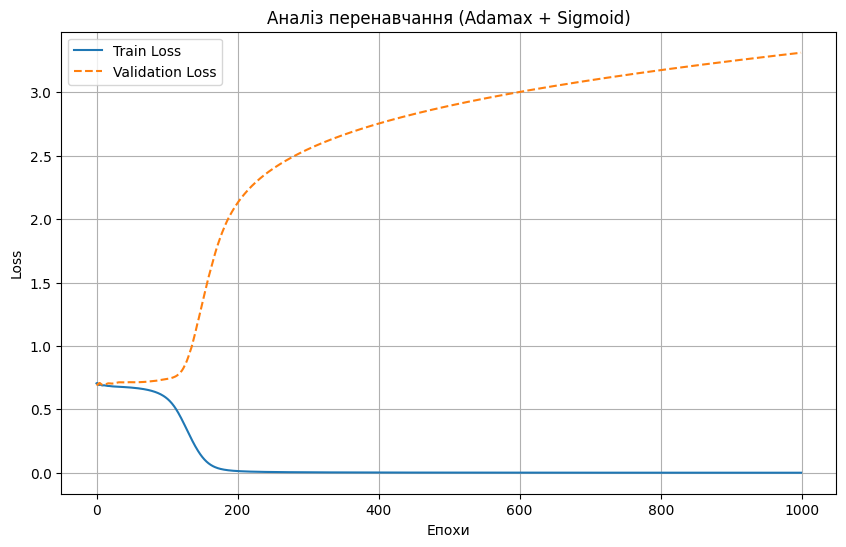

Optimizer: Nadam, Function: Sigmoid, Epoch [5/1000], Train Loss: 0.6906, Validation Loss: 0.6945, Acc: 0.49494948983192444
Optimizer: Nadam, Function: Sigmoid, Epoch [10/1000], Train Loss: 0.6868, Validation Loss: 0.6977, Acc: 0.5202020406723022
--- [INFO] Early stopping triggered at epoch 12 for Nadam ---


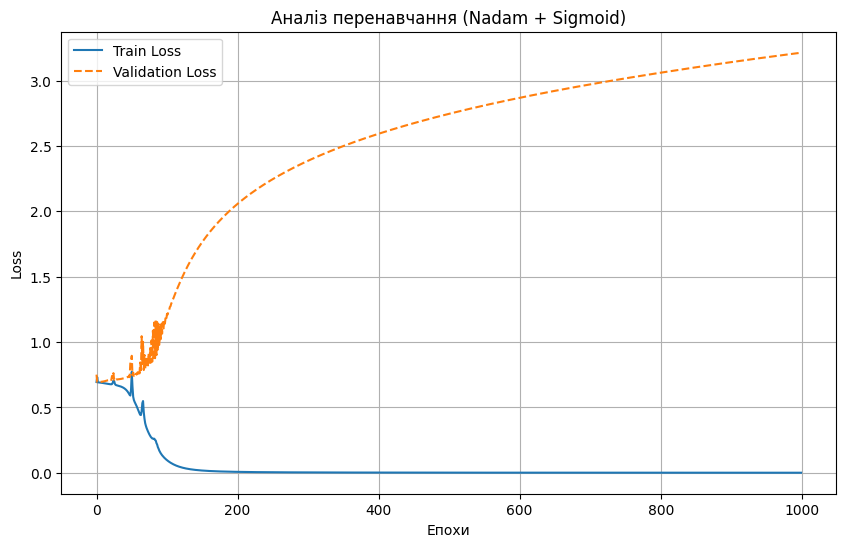

Optimizer: SGD, Function: Tanh, Epoch [5/1000], Train Loss: 0.6949, Validation Loss: 0.6951, Acc: 0.502525269985199
Optimizer: SGD, Function: Tanh, Epoch [10/1000], Train Loss: 0.6947, Validation Loss: 0.6951, Acc: 0.502525269985199
Optimizer: SGD, Function: Tanh, Epoch [15/1000], Train Loss: 0.6945, Validation Loss: 0.6951, Acc: 0.502525269985199
Optimizer: SGD, Function: Tanh, Epoch [20/1000], Train Loss: 0.6944, Validation Loss: 0.6951, Acc: 0.5
Optimizer: SGD, Function: Tanh, Epoch [25/1000], Train Loss: 0.6942, Validation Loss: 0.6951, Acc: 0.5
Optimizer: SGD, Function: Tanh, Epoch [30/1000], Train Loss: 0.6940, Validation Loss: 0.6950, Acc: 0.4974747598171234
Optimizer: SGD, Function: Tanh, Epoch [35/1000], Train Loss: 0.6938, Validation Loss: 0.6950, Acc: 0.49494948983192444
Optimizer: SGD, Function: Tanh, Epoch [40/1000], Train Loss: 0.6937, Validation Loss: 0.6950, Acc: 0.5075757503509521
Optimizer: SGD, Function: Tanh, Epoch [45/1000], Train Loss: 0.6935, Validation Loss: 0.6

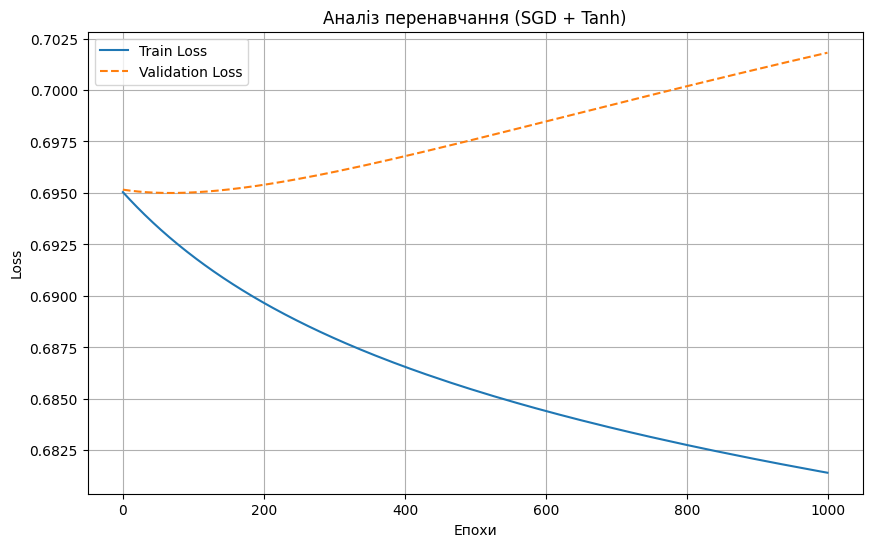

Optimizer: RMSprop, Function: Tanh, Epoch [5/1000], Train Loss: 1.0094, Validation Loss: 0.8502, Acc: 0.49494948983192444
Optimizer: RMSprop, Function: Tanh, Epoch [10/1000], Train Loss: 0.6465, Validation Loss: 0.7113, Acc: 0.5555555820465088
Optimizer: RMSprop, Function: Tanh, Epoch [15/1000], Train Loss: 0.6025, Validation Loss: 0.7302, Acc: 0.5681818127632141
--- [INFO] Early stopping triggered at epoch 16 for RMSprop ---


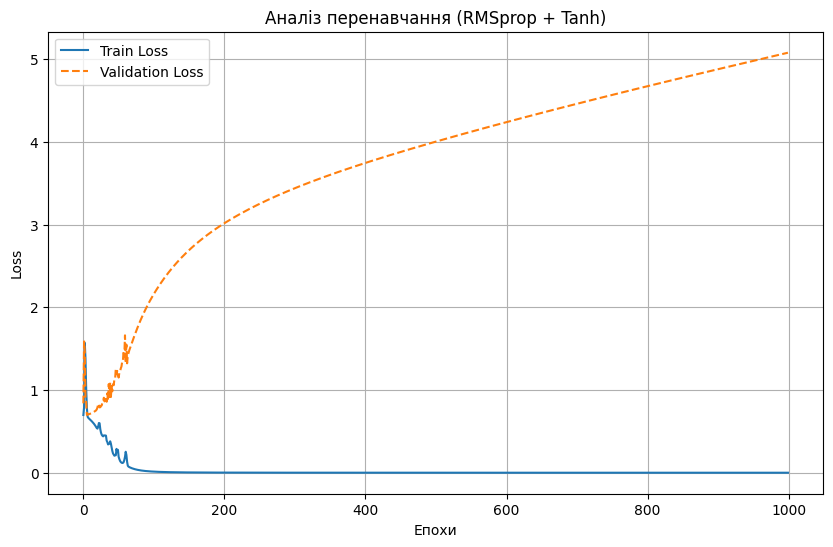

Optimizer: Adam, Function: Tanh, Epoch [5/1000], Train Loss: 0.6770, Validation Loss: 0.7130, Acc: 0.5707070827484131
Optimizer: Adam, Function: Tanh, Epoch [10/1000], Train Loss: 0.6508, Validation Loss: 0.7101, Acc: 0.5631313323974609
--- [INFO] Early stopping triggered at epoch 11 for Adam ---


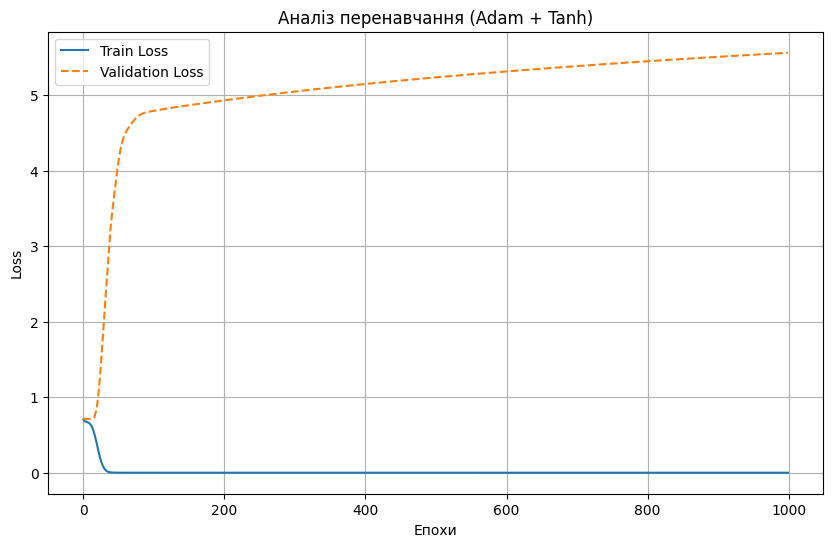

Optimizer: Adadelta, Function: Tanh, Epoch [5/1000], Train Loss: 0.6940, Validation Loss: 0.6942, Acc: 0.4040403962135315
Optimizer: Adadelta, Function: Tanh, Epoch [10/1000], Train Loss: 0.6854, Validation Loss: 0.6965, Acc: 0.49242424964904785
Optimizer: Adadelta, Function: Tanh, Epoch [15/1000], Train Loss: 0.6819, Validation Loss: 0.7006, Acc: 0.5378788113594055
--- [INFO] Early stopping triggered at epoch 16 for Adadelta ---


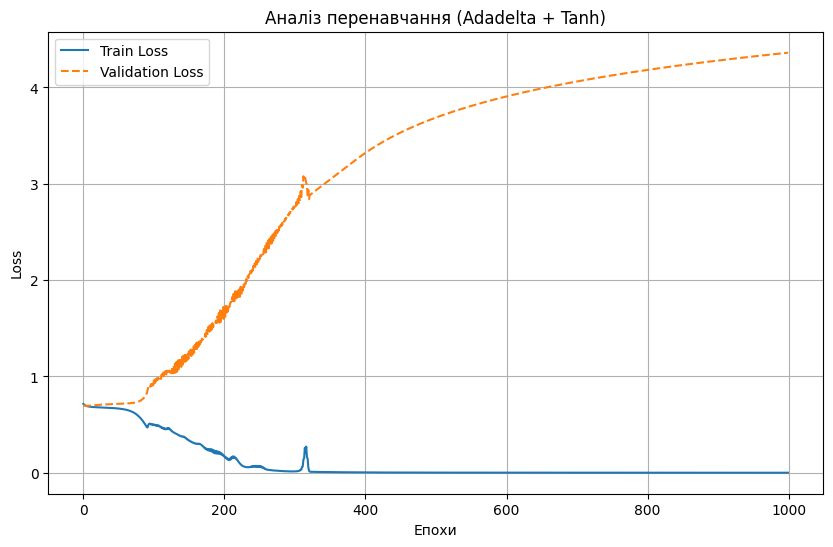

Optimizer: Adagrad, Function: Tanh, Epoch [5/1000], Train Loss: 0.6737, Validation Loss: 0.7080, Acc: 0.5227272510528564
Optimizer: Adagrad, Function: Tanh, Epoch [10/1000], Train Loss: 0.6549, Validation Loss: 0.7165, Acc: 0.5277777910232544
--- [INFO] Early stopping triggered at epoch 11 for Adagrad ---


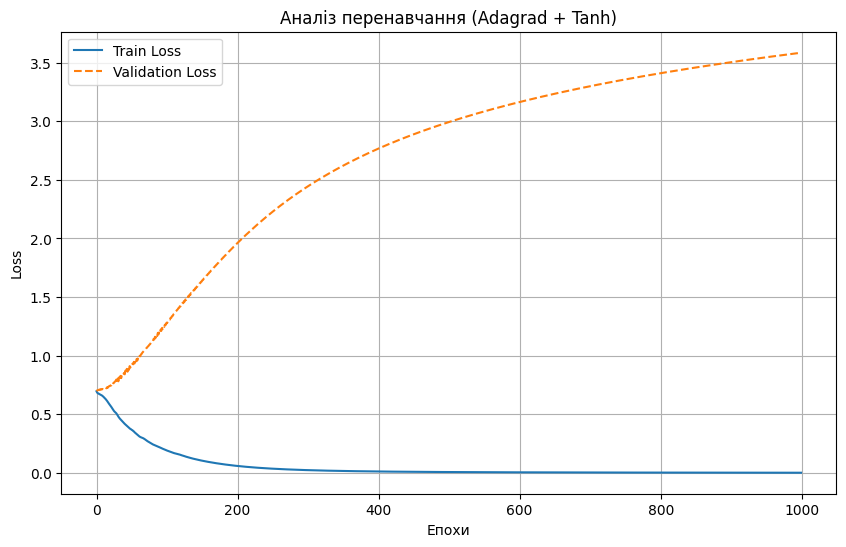

Optimizer: Adamax, Function: Tanh, Epoch [5/1000], Train Loss: 0.6771, Validation Loss: 0.7176, Acc: 0.5378788113594055
Optimizer: Adamax, Function: Tanh, Epoch [10/1000], Train Loss: 0.6635, Validation Loss: 0.7184, Acc: 0.5454545617103577
--- [INFO] Early stopping triggered at epoch 11 for Adamax ---


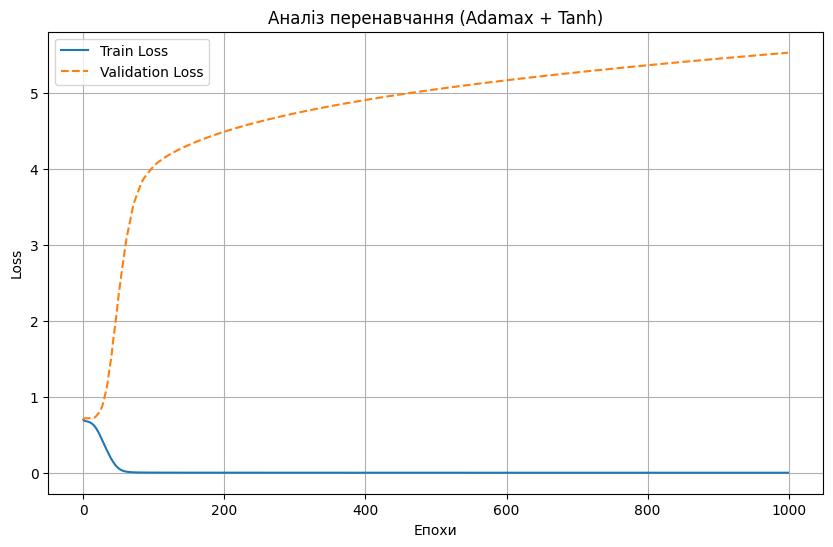

Optimizer: Nadam, Function: Tanh, Epoch [5/1000], Train Loss: 0.6757, Validation Loss: 0.7081, Acc: 0.5378788113594055
Optimizer: Nadam, Function: Tanh, Epoch [10/1000], Train Loss: 0.6559, Validation Loss: 0.7561, Acc: 0.5429292917251587
--- [INFO] Early stopping triggered at epoch 11 for Nadam ---


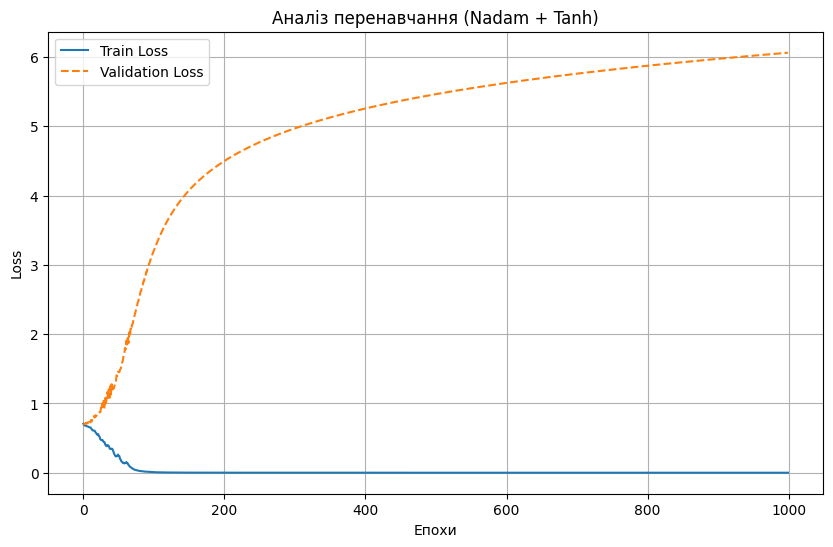

In [36]:
for activation_function_name in activation_function_names:
    for optimizer in optimizer_names:
        perform_learning_analysis(1000, optimizer, activation_function_name)
        

In [37]:
print("\n" + "="*30)
print("ФІНАЛЬНІ РЕЗУЛЬТАТИ НА ТЕСТОВІЙ ВИБІРЦІ (Individual)")
best_model.eval()
with torch.no_grad():
    test_logits = best_model(X_test_scaled_tensor)
    _, test_predictions = torch.max(test_logits, 1)

from sklearn.metrics import classification_report
print(classification_report(y_test_tensor.squeeze().long(), test_predictions))


ФІНАЛЬНІ РЕЗУЛЬТАТИ НА ТЕСТОВІЙ ВИБІРЦІ (Individual)
              precision    recall  f1-score   support

           0       0.10      0.07      0.08        45
           1       0.75      0.83      0.79       155

    accuracy                           0.66       200
   macro avg       0.43      0.45      0.44       200
weighted avg       0.61      0.66      0.63       200

